# 3. Linear Maps
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Three maps of the plane applied to the same grid and unit circle. A linear map (left) fixes the origin and keeps grid lines straight, parallel and evenly spaced. An affine map (middle) is a linear map followed by a translation; it is not linear because it moves the origin. A nonlinear map (right) bends lines and spaces them unevenly.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


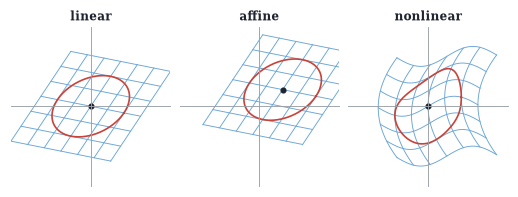

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *

A = np.array([[1.0, 0.6], [-0.2, 0.9]])
maps = [("linear", lambda P: A @ P),
        ("affine", lambda P: A @ P + np.array([[0.7], [0.5]])),
        ("nonlinear", lambda P: np.vstack([P[0] + 0.25 * P[1] ** 2, P[1] + 0.3 * np.sin(2 * P[0])]))]
fig, axs = plt.subplots(1, 3, figsize=(W, 1.7))
t = np.linspace(-1.5, 1.5, 120)
for ax, (name, f) in zip(axs, maps):
    plane(ax, 2.4, grid=False)
    for c in np.linspace(-1.5, 1.5, 7):
        for P in (np.vstack([t, c + 0 * t]), np.vstack([c + 0 * t, t])):
            ax.plot(*f(P), color=SKY, lw=0.6)
    th = np.linspace(0, 2 * np.pi, 200)
    ax.plot(*f(np.vstack([np.cos(th), np.sin(th)])), color=RED, lw=1.1)
    o = f(np.zeros((2, 1)))
    ax.plot(*o, "o", color=INK, ms=3)
    ax.set_title(name)

A linear map of the plane is completely specified by two arrows, the images $Te_1$ and $Te_2$ of the standard basis. Everything else follows: here $v=2e_1+e_2$ must go to $2\,Te_1+Te_2$, and the whole grid follows suit.

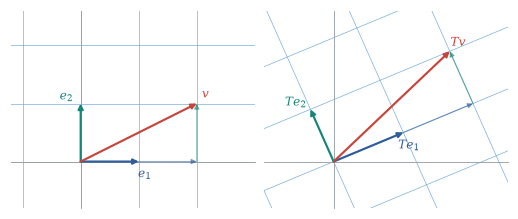

In [3]:
Te1, Te2 = np.array([1.2, 0.5]), np.array([-0.4, 0.9])
T = np.column_stack([Te1, Te2])
fig, axs = plt.subplots(1, 2, figsize=(W, 2.2))
v = np.array([2.0, 1.0])
for ax, M, lab in [(axs[0], np.eye(2), ("e_1", "e_2", "v")), (axs[1], T, ("Te_1", "Te_2", "Tv"))]:
    plane(ax, (-1.2, 3, -0.8, 2.6), grid=False)
    grid_image(ax, M, lim=3, n=7, color=SKY, lw=0.45, base=False)
    arrow(ax, M[:, 0], color=BLUE, label=f"${lab[0]}$", offset=(0.1, -0.22))
    arrow(ax, M[:, 1], color=TEAL, label=f"${lab[1]}$", offset=(-0.25, 0.12))
    arrow(ax, 2 * M[:, 0], color=BLUE, lw=0.8, alpha=0.5)
    arrow(ax, M[:, 1], origin=2 * M[:, 0], color=TEAL, lw=0.8, alpha=0.5)
    arrow(ax, M @ v, color=RED, label=f"${lab[2]}$", offset=(0.15, 0.15))

Composition is not commutative. A shape (grey) is rotated by $45^\circ$ and sheared horizontally; the two orders produce different results. Only special pairs of maps commute, for instance two rotations, or two scalings along the same axes.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


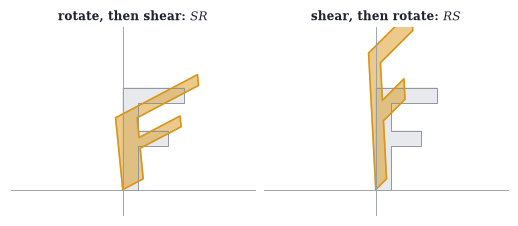

In [4]:
th = np.pi / 4
R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
S = np.array([[1.0, 0.9], [0.0, 1.0]])
F = np.array([[0, 0], [0, 2], [1.2, 2], [1.2, 1.7], [0.3, 1.7], [0.3, 1.15], [0.9, 1.15], [0.9, 0.85], [0.3, 0.85], [0.3, 0], [0, 0]]).T
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
for ax, M, title in [(axs[0], S @ R, "rotate, then shear: $SR$"), (axs[1], R @ S, "shear, then rotate: $RS$")]:
    plane(ax, (-2.2, 2.6, -0.5, 3.2), grid=False)
    ax.fill(*F, color=LIGHT); ax.plot(*F, color=GRAY, lw=0.6)
    G = M @ F
    ax.fill(*G, color=GOLD, alpha=0.5); ax.plot(*G, color=GOLD, lw=1.0)
    ax.set_title(title)

The linear functional $T(x,y)=x+2y$ on $\R^2$. Its null space (bold) is a line through the origin. Every other level set $\{T=c\}$ is a parallel line, a translate $v_0+\nul T$ of the null space. Two points on the same line are indistinguishable to $T$.

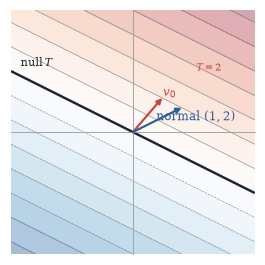

In [5]:
fig, ax = plt.subplots(figsize=(W * 0.6, 2.3))
plane(ax, 2.5, grid=False)
xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 300), np.linspace(-2.5, 2.5, 300))
cs = ax.contourf(xx, yy, xx + 2 * yy, levels=np.arange(-8, 9, 1), cmap="RdBu_r", alpha=0.35)
ax.contour(xx, yy, xx + 2 * yy, levels=np.arange(-7, 8, 1), colors=[GRAY], linewidths=0.4)
ax.contour(xx, yy, xx + 2 * yy, levels=[0], colors=[INK], linewidths=1.6)
ax.text(-2.3, 1.35, r"$\mathrm{null}\,T$", fontsize=7.5)
v0 = np.array([0.6, 0.7]); arrow(ax, v0, color=RED, label="$v_0$", offset=(0.15, 0.1))
ax.text(1.3, 1.25, r"$T=2$", fontsize=6.5, color=RED)
arrow(ax, (1, 0.5), color=BLUE, label=r"normal $(1,2)$", offset=(0.3, -0.2))

Rank–nullity for a map $T:\R^3\to\R^3$ of rank $2$. Left, the domain: the null space is a line (red) and a complementary plane $U$ (blue) is mapped faithfully. Right, the image of a cube: the whole cube is flattened onto the range, a plane. Every segment parallel to the null space collapses to a point. Here $3=1+2$.

[]

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


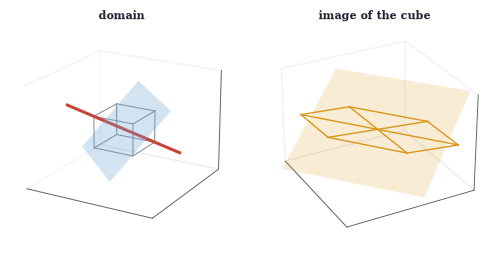

In [6]:
A = np.array([[1.0, 0.5, 1.5], [0.2, 1.0, 1.2], [0.4, -0.3, 0.1]])
A[2] = 0.3 * A[0] - 0.4 * A[1]                         # force rank 2
n = np.linalg.svd(A)[2][-1]                           # null space direction
fig = plt.figure(figsize=(W, 2.2))
ax = ax3d(fig, pos=121, elev=20, azim=-60, lim=1.6)
corners = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) - 0.5
edges = [(a, b) for a in range(8) for b in range(a + 1, 8) if np.sum(np.abs(corners[a] - corners[b])) == 1]
for a, b in edges:
    ax.plot(*np.vstack([corners[a], corners[b]]).T, color=GRAY, lw=0.7)
t = np.array([-1.6, 1.6]); ax.plot(*np.outer(n, t), color=RED, lw=2)
u1, u2 = np.linalg.svd(A)[2][:2]
s, r = np.meshgrid([-1.2, 1.2], [-1.2, 1.2]); P = s[..., None] * u1 + r[..., None] * u2
ax.plot_surface(P[..., 0], P[..., 1], P[..., 2], color=SKY, alpha=0.3, lw=0, shade=False)
ax.set_title("domain", fontsize=7, pad=-2); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
nrm = np.linalg.svd(A)[0][:, 2]                       # normal of the range plane
if nrm[2] < 0: nrm = -nrm
el, az = np.degrees(np.arcsin(nrm[2])), np.degrees(np.arctan2(nrm[1], nrm[0]))
ax = ax3d(fig, pos=122, elev=el - 35, azim=az + 25, lim=1.6)   # look obliquely at the plane
Ac = corners @ A.T
for a, b in edges:
    ax.plot(*np.vstack([Ac[a], Ac[b]]).T, color=GOLD, lw=0.9)
r1, r2 = np.linalg.svd(A)[0][:, :2].T
P = s[..., None] * r1 * 1.4 + r[..., None] * r2 * 1.4
ax.plot_surface(P[..., 0], P[..., 1], P[..., 2], color=GOLD, alpha=0.18, lw=0, shade=False)
ax.set_title("image of the cube", fontsize=7, pad=-2); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

In [7]:
# Rank-nullity numerically for random maps, and the bottleneck of a deep linear network.
rng = np.random.default_rng(1)
for m, n, r in [(4, 6, 3), (5, 5, 5), (7, 3, 2)]:
    A = rng.normal(size=(m, r)) @ rng.normal(size=(r, n))     # an m x n map of rank r
    rank = np.linalg.matrix_rank(A)
    nullity = n - rank
    # an explicit null space basis from the SVD: right singular vectors beyond the rank
    Nb = np.linalg.svd(A)[2][rank:].T
    print(f"{m}x{n}: rank {rank}, nullity {nullity}, rank+nullity = {rank + nullity} = n,"
          f" max |A @ nullbasis| = {np.abs(A @ Nb).max() if nullity else 0:.1e}")
widths = [512, 256, 32, 256, 512]                              # a linear 'autoencoder'
M = np.eye(widths[0])
for a, b in zip(widths[:-1], widths[1:]):
    M = rng.normal(size=(b, a)) / np.sqrt(a) @ M
print("rank of the 512 x 512 end-to-end map:", np.linalg.matrix_rank(M))

4x6: rank 3, nullity 3, rank+nullity = 6 = n, max |A @ nullbasis| = 2.8e-16
5x5: rank 5, nullity 0, rank+nullity = 5 = n, max |A @ nullbasis| = 0.0e+00
7x3: rank 2, nullity 1, rank+nullity = 3 = n, max |A @ nullbasis| = 5.5e-16
rank of the 512 x 512 end-to-end map: 32


Differentiation $D$ as a linear map on $\Poly_3(\R)$. Each polynomial on the left (degree $\le 3$) is sent to its derivative on the right (degree $\le 2$). The constant polynomial (grey) is sent to $0$: the null space is one-dimensional, the range three-dimensional, and $4=1+3$.

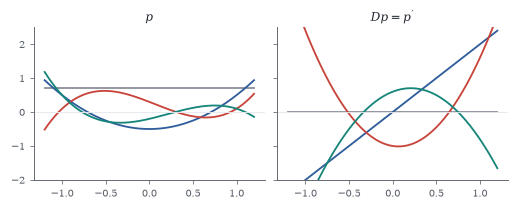

In [8]:
x = np.linspace(-1.2, 1.2, 300)
ps = [np.poly1d([0.7]), np.poly1d([1, 0, -0.5]), np.poly1d([1, -0.2, -1, 0.3]), np.poly1d([-0.8, 0.5, 0.6, -0.2])]
cols = [GRAY, BLUE, RED, TEAL]
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8), sharey=True)
for p, c in zip(ps, cols):
    axs[0].plot(x, p(x), color=c); axs[1].plot(x, p.deriv()(x), color=c)
for ax, t in zip(axs, ["$p$", "$Dp=p'$"]):
    ax.axhline(0, color=LIGHT, lw=0.6); ax.set_title(t); ax.set_ylim(-2, 2.5)

Level sets of the homogeneous but non-linear function $\varphi(x,y)=(x^3+y^3)^{1/3}$ (left) are scaled copies of a curved line, whereas those of the linear functional $x+y$ (right) are parallel straight lines. Homogeneity controls behaviour along rays from the origin; additivity is what straightens the level sets.

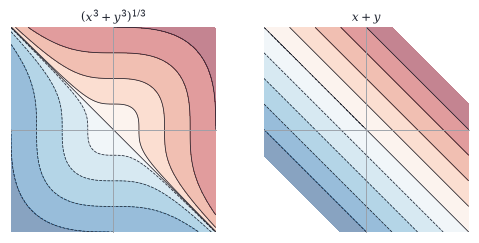

In [9]:
xx, yy = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-2, 2, 400))
phi = np.cbrt(xx ** 3 + yy ** 3)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
for ax, F, t in [(axs[0], phi, r"$(x^3+y^3)^{1/3}$"), (axs[1], xx + yy, "$x+y$")]:
    plane(ax, 2, grid=False)
    ax.contourf(xx, yy, F, levels=np.linspace(-2.5, 2.5, 11), cmap="RdBu_r", alpha=0.5)
    ax.contour(xx, yy, F, levels=np.linspace(-2, 2, 9), colors=[INK], linewidths=0.5)
    ax.set_title(t)

The map $T(x,y)=(y,0)$ on $\R^2$ has range equal to its null space, the horizontal axis. Every vector is first pushed onto the axis (blue arrows show $v\mapsto Tv$), and the axis itself is then crushed to the origin: $T^2=0$.

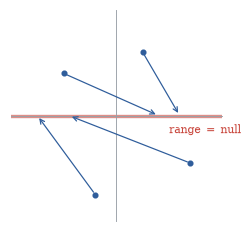

In [10]:
fig, ax = plt.subplots(figsize=(W * 0.55, 2.0))
plane(ax, 2, grid=False)
ax.plot([-2, 2], [0, 0], color=RED, lw=2.2, alpha=0.6)
ax.text(1.0, -0.35, r"range $=$ null", color=RED, fontsize=7)
for v in [(0.5, 1.2), (-1.0, 0.8), (1.4, -0.9), (-0.4, -1.5)]:
    v = np.array(v); Tv = np.array([v[1], 0])
    ax.plot(*v, "o", color=BLUE, ms=3)
    ax.annotate("", xy=Tv, xytext=v, arrowprops=dict(arrowstyle="->", color=BLUE, lw=0.8))

In [11]:
S = np.diag([1, 1, 0, 0, 0.0])
T = np.zeros((5, 5)); T[2, 0] = 1; T[3, 1] = 1
print("ST = 0:", np.allclose(S @ T, 0), "  rank TS =", np.linalg.matrix_rank(T @ S))

ST = 0: True   rank TS = 2


An oblique projection $P$ ($P^2=P$) onto the line $\range P$ along the line $\nul P$. Each vector $v$ splits as $Pv+(v-Pv)$, and $v-Pv$ is parallel to the null space. Applying $P$ again changes nothing.

P^2 = P: True


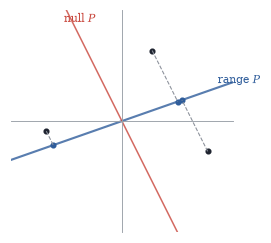

In [12]:
r = np.array([1.0, 0.35]); k = np.array([-0.5, 1.0])
B = np.column_stack([r, k]); P = B @ np.diag([1, 0]) @ np.linalg.inv(B)
fig, ax = plt.subplots(figsize=(W * 0.6, 2.1))
plane(ax, 2.2, grid=False)
span_line(ax, r, lim=3, color=BLUE, lw=1.4); ax.text(1.9, 0.75, r"range $P$", color=BLUE, fontsize=7)
span_line(ax, k, lim=3, color=RED, lw=1.0); ax.text(-1.15, 1.95, r"null $P$", color=RED, fontsize=7)
for v in [np.array([0.6, 1.4]), np.array([1.7, -0.6]), np.array([-1.5, -0.2])]:
    ax.plot(*v, "o", color=INK, ms=3); ax.plot(*(P @ v), "o", color=BLUE, ms=3)
    ax.plot(*np.vstack([v, P @ v]).T, color=GRAY, ls="--", lw=0.7)
print("P^2 = P:", np.allclose(P @ P, P))

In [13]:
# Solve 5q'' + 3q' = p for p(x) = x^3 - 2x + 1 by linear algebra on coefficient vectors.
from numpy.polynomial import Polynomial as Poly
m = 3
L_op = lambda q: 5 * q.deriv(2) + 3 * q.deriv(1)
# matrix of L : P_{m+1} -> P_m in the monomial bases (column k = coefficients of L(x^k))
L = np.zeros((m + 1, m + 2))
for k in range(m + 2):
    c = L_op(Poly.basis(k)).coef
    L[:len(c), k] = c if k > 0 else 0
print("rank of L:", np.linalg.matrix_rank(L), " (domain dim", m + 2, ", nullity 1: the constants)")
p = Poly([1.0, -2.0, 0.0, 1.0])
q = Poly(np.linalg.lstsq(L, p.coef, rcond=None)[0])
print("q =", q)
print("residual coefficients of 5q''+3q' - p:", np.round((L_op(q) - p).coef, 12))

rank of L: 4  (domain dim 5 , nullity 1: the constants)
q = 8.96505092e-15 - 7.81481481·x + 2.44444444·x² - 0.55555556·x³ +
0.08333333·x⁴
residual coefficients of 5q''+3q' - p: [0. 0. 0. 0.]
